# 06 · vLLM disaggregated prefill/decode: ScuffedRdmaConnector TTFT

KV cache transfer for disaggregated prefill (server 1) / decode (server 2) through `ScuffedRdmaConnector`
(`middleware/vllm_plugin/`), compared against vLLM's `NixlConnector` (UCX backend and LIBFABRIC backend), the same connector over TCP,
and a single non-disaggregated server.

- **local**: runs the connector test suite, then pushes a Granite 3.3-2B shaped KV cache between two processes
  through the connector's own data path (no vLLM, no GPU), over TCP and over the libfabric pool when it is built.
  Numbers from this mode are smoke tests of the code path, not results.
- **cluster**: prints the serve/proxy commands for each setup (start them in terminals on each node), checks the
  cross-node transport with the loopback tool, runs the TTFT/ITL sweep against every endpoint, and plots p50/p99
  against prompt length. Results land in `benchmarks/results/vllm_disagg/`.

**README sections covered:** [7. ScuffedRdmaConnector inside vLLM](../docs/explained/07-connector.md)

Figures are written to `docs/figures/` (model figures: arithmetic, proofs and repo results) and `docs/figures/<MODE>/` (measured on the machine that ran the notebook).

In [1]:
MODE = "local"            # "local": tests + loopback on this machine; "cluster": real vLLM on server 1 / server 2
PREFILL_HOST = "server1"
DECODE_HOST = "server2"
MODEL = "ibm-granite/granite-3.3-2b-instruct"
TRANSPORT = "fabric"       # fabric | tcp
PROVIDER = "verbs"         # libfabric provider for TRANSPORT="fabric" (verbs on SoftRoCE; tcp/shm work anywhere)
EP_TYPE = "msg"            # msg | rdm
RESULTS_SUBDIR = "vllm_disagg"
KV_PORT = 14600
# cluster-mode sweep targets: label -> base URL (proxy for disagg setups, server for "single")
ENDPOINTS = {
    "single": "http://localhost:8300",
    "nixl": "http://localhost:8001",
    "nixl-libfabric": "http://localhost:8003",
    "scuffed-tcp": "http://localhost:8002",
    "scuffed-fabric-verbs": "http://localhost:8000",
}
PROMPT_LENS = [128, 512, 1024, 2048, 4096]
N_PER_LEN = 20
MAX_TOKENS = 64
WAIT_FOR_SERVERS_S = 0      # >0: poll /health on every endpoint before sweeping

In [2]:
import os, sys, json, socket, subprocess, time
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "middleware").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
HOST = socket.gethostname()
STAMP = time.strftime("%Y%m%dT%H%M%SZ", time.gmtime())
RESULTS = (ROOT / "benchmarks" / "results" / RESULTS_SUBDIR) if MODE == "cluster" else Path("/tmp/scuffed-local") / RESULTS_SUBDIR
RESULTS.mkdir(parents=True, exist_ok=True)
FIGDIR = ROOT / "docs" / "figures"
(FIGDIR / MODE).mkdir(parents=True, exist_ok=True)

import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "legend.fontsize": 7.5, "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 1.4,
    "lines.markersize": 4, "figure.constrained_layout.use": False})
C = {"hot": "#f97316", "cold": "#38bdf8", "spill": "#a78bfa", "ok": "#34d399", "bad": "#f43f5e",
     "gold": "#facc15", "ink": "#1f2937", "muted": "#94a3b8"}

def fig(name, model=False, caption=None, f=None):
    """Save the current figure as PNG + PDF and show it.
    model=True: arithmetic or repo results, same on every machine -> docs/figures/<name>
    model=False: measured on this machine -> docs/figures/<MODE>/<name>"""
    f = f or plt.gcf()
    d = FIGDIR if model else FIGDIR / MODE
    f.tight_layout()
    for ext in ("png", "pdf"):
        f.savefig(d / f"{name}.{ext}", bbox_inches="tight")
    print(f"figure -> {d.relative_to(ROOT)}/{name}.png" + (f"  |  {caption}" if caption else ""))
    plt.show()

def save(name, obj):
    p = RESULTS / f"{HOST}_{name}.json"
    obj = {"host": HOST, "utc": STAMP, "mode": MODE, **obj}
    p.write_text(json.dumps(obj, indent=2, default=str))
    print("wrote", p)
    return p

def sh(cmd, check=True):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True, cwd=ROOT)
    print(r.stdout[-4000:], r.stderr[-2000:])
    if check and r.returncode:
        raise RuntimeError(f"{cmd} -> {r.returncode}")
    return r
print("repo:", ROOT, "| host:", HOST, "| mode:", MODE, "| results ->", RESULTS, "| figures ->", FIGDIR)

repo: /home/claude/scuffedrdma | host: vm | mode: local | results -> /tmp/scuffed-local/vllm_disagg | figures -> /home/claude/scuffedrdma/docs/figures


## Math: what the connector guarantees, and what staging costs

**Section 7.** The connector keys every transfer by a proxy-generated `xfer_id` (vLLM renames requests internally, so the prefill and decode engines name the same request differently). With 122 random bits per UUID, the chance that any two of $n$ ids collide is at most $n^2/2^{123}$: about $10^{-19}$ for $n = 10^9$ requests. Each attention layer's blocks are gathered, encoded (raw bf16 or scuffedQuant), and queued as one blob `<xfer_id>/<layer>` on the sender; decode waits per layer with a deadline, reports blocks that never arrived through `get_block_ids_with_load_errors`, and vLLM recomputes those. So a lost layer degrades to recomputation, never to a wrong answer, and a request waits at most $L \times$ `load_timeout_s` ([docs/explained/07](../docs/explained/07-connector.md)).

**Host staging.** None of the lab servers has a GPUDirect path, so every layer is copied GPU → host before it is sent and host → GPU after it arrives. For a layer of $b$ bytes over PCIe with effective rate $P$ and a wire of rate $C$,

$$
t_{\text{copy}} = \frac{b}{P}, \qquad t_{\text{wire}} = \frac{8b}{C}, \qquad \frac{t_{\text{copy}}}{t_{\text{wire}}} = \frac{C}{8P},
$$

which is independent of $b$: at $P = 20$ GB/s and $C = 10$ Gb/s the copy is about 6% of the wire time per layer; at 100 Gb/s it would be 63%. The first figure below plots both against layer size; notebook 08 times the real copies on the GPU.

The connector tests, the two-process loopback and the TTFT runner self-test run anywhere; the cross-node TTFT sweep is E8 and needs the servers.

## 0. Staging cost model (model figure)

figure -> docs/figures/07_staging_cost.png  |  copy/wire ratio = C/(8P), independent of size


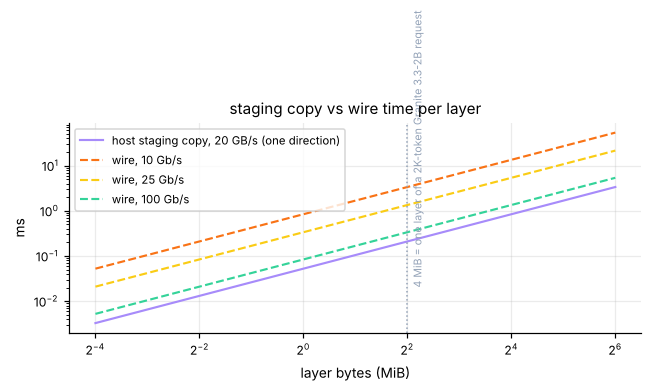

copy / wire at 10 Gb/s: 6.2%; at 100 Gb/s: 62%


In [3]:
import numpy as np
b = 2.0 ** np.arange(16, 27)                      # 64 KiB .. 64 MiB per layer
P = 20e9                                           # effective PCIe copy rate, bytes/s (assumed; measured in notebook 08)
figst, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(b / 2**20, b / P * 1e3, color=C["spill"], label="host staging copy, 20 GB/s (one direction)")
for rate, col in ((10e9, C["hot"]), (25e9, C["gold"]), (100e9, C["ok"])):
    ax.plot(b / 2**20, 8 * b / rate * 1e3, color=col, ls="--", label=f"wire, {rate/1e9:.0f} Gb/s")
ax.axvline(4, color=C["muted"], ls=":", lw=1); ax.text(4.2, 0.02, "4 MiB = one layer of a 2K-token Granite 3.3-2B request", fontsize=7, rotation=90, va="bottom", color=C["muted"])
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel("layer bytes (MiB)"); ax.set_ylabel("ms"); ax.legend(); ax.set_title("staging copy vs wire time per layer")
fig("07_staging_cost", model=True, caption="copy/wire ratio = C/(8P), independent of size")
print(f"copy / wire at 10 Gb/s: {10e9 / (8 * P):.1%}; at 100 Gb/s: {100e9 / (8 * P):.0%}")

## 1. Connector tests

Scheduler bookkeeping, block gather/scatter for every KV layout, codec (bfloat16, scuffedQuant), producer to consumer through the real connector class, proxy, TTFT runner. The two vLLM-import tests run when vLLM is installed (cluster) or its source is on `VLLM_SRC`.

In [4]:
r = sh("python3 -m pytest -q -rs -p no:warnings tests/test_vllm_connector.py", check=False)
assert r.returncode == 0, "connector tests failed"

$ python3 -m pytest -q -rs -p no:warnings tests/test_vllm_connector.py


..........................ss....                                         [100%]
=========================== short test summary info ============================
SKIPPED [1] tests/test_vllm_connector.py:530: vllm not installed here; runs on the cluster
SKIPPED [1] tests/test_vllm_connector.py:539: vllm not importable here
 


## 2. Loopback through the connector data path

`take_blocks -> encode_kv -> KVSender -> BlobChannel -> KVReceiver -> decode_kv -> put_blocks`, Granite 3.3-2B cache shape (40 layers, 8 KV heads, head_dim 64, bfloat16), FlashAttention layout. Consumer runs in a child process. Every request is checked by SHA-256 on both sides.

In [5]:
from middleware.vllm_plugin.loopback import default_args, run_both
if MODE == "local":
    lb_lens, lb_layers = [128, 512], 8
else:
    lb_lens, lb_layers = [128, 512, 2048, 4096], 40
loop = {}
for tr, prov in [("tcp", None), ("fabric", "tcp" if MODE == "local" else PROVIDER)]:
    out = run_both(default_args(layers=lb_layers, prompt_lens=lb_lens, transport=tr, provider=prov,
                                ep_type=EP_TYPE if tr == "fabric" else None, num_blocks=512))
    used = (out["producer"]["transport"], out["consumer"]["transport"])
    loop[f"{tr}:{prov}"] = out
    print(f"{tr:6s} provider={prov} used={used} all_match={out['all_match']}")
    for p, c in zip(out["producer"]["requests"], out["consumer"]["requests"]):
        print(f"   prompt {p['prompt_len']:5d}  push {p['push_ms']:8.2f} ms  load {c['load_ms']:8.2f} ms  "
              f"blocks {c['blocks_written']}")
    assert out["all_match"], "KV mismatch after transfer"
save("loopback", {"note": "same-host two-process loopback; smoke test of the connector data path",
                  "runs": {k: {"producer": v["producer"]["requests"], "consumer": v["consumer"]["requests"],
                               "transport": [v["producer"]["transport"], v["consumer"]["transport"]],
                               "producer_telemetry": v["producer"]["telemetry"]} for k, v in loop.items()}})

tcp    provider=None used=('tcp', 'tcp') all_match=True
   prompt   128  push     7.30 ms  load    12.98 ms  blocks 64
   prompt   512  push    38.40 ms  load    33.26 ms  blocks 256


fabric provider=tcp used=('fabric', 'fabric') all_match=True
   prompt   128  push    10.61 ms  load    84.09 ms  blocks 64
   prompt   512  push    27.11 ms  load    42.88 ms  blocks 256
wrote /tmp/scuffed-local/vllm_disagg/vm_loopback.json


PosixPath('/tmp/scuffed-local/vllm_disagg/vm_loopback.json')

### Telemetry from the loopback producer

Per-class (hot/cold) ops, bytes and completion latency as reported to `middleware.telemetry` by `KVSender`. KV layers land in cold, the `__done__` control blobs in hot.

In [6]:
rows = []
for k, v in loop.items():
    for cls, s in v["producer"]["telemetry"]["classes"].items():
        rows.append({"run": k, "class": cls, "ops": s["ops"], "bytes": s["bytes"],
                     "p50_us": s["p50_us"], "p99_us": s["p99_us"]})
try:
    import pandas as pd
    display(pd.DataFrame(rows))
except ImportError:
    for r in rows:
        print(r)

,run,class,ops,bytes,p50_us,p99_us
0,tcp:None,cold,16,10489864,329.6770,5445.65025
1,tcp:None,cold_queued,16,0,3293.3345,9646.35800
2,tcp:None,hot,2,82,1830.4350,3619.69450
3,tcp:None,hot_queued,2,0,4227.7330,7442.40838
4,fabric:tcp,cold,16,10489864,646.8595,1095.66590
5,fabric:tcp,cold_queued,16,0,691.6985,1277.35620
6,fabric:tcp,hot,2,82,76.3390,97.33354
7,fabric:tcp,hot_queued,2,0,607.1005,1024.87499


## 3. Cluster: start the servers

Run each block in a terminal on the named node (decode first). Each setup uses its own ports so they can stay up together if memory allows; otherwise run one setup at a time and edit `ENDPOINTS`.

Cross-node transport check without vLLM (run before the servers):

```
server2$  python -m middleware.vllm_plugin.loopback --role consumer --port 14600 --transport fabric --provider verbs
server1$ python -m middleware.vllm_plugin.loopback --role producer --peer server2 --port 14600 --transport fabric --provider verbs
```

In [7]:
setups = {
    "scuffed-fabric-verbs": dict(CONNECTOR="scuffed", TRANSPORT=TRANSPORT, PROVIDER=PROVIDER, EP_TYPE=EP_TYPE,
                                 PROXY_PORT=8000, KV_PORT=KV_PORT),
    "scuffed-tcp": dict(CONNECTOR="tcp", PROXY_PORT=8002, KV_PORT=KV_PORT + 100, PREFILL_PORT=8102, DECODE_PORT=8202),
    "nixl": dict(CONNECTOR="nixl", PROXY_PORT=8001, PREFILL_PORT=8101, DECODE_PORT=8201),
    # NIXL's LIBFABRIC backend picks cxi > efa > tcp > sockets, so on these nodes it runs over libfabric tcp.
    # Its README lists libfabric >= 1.21 and GPUDirect RDMA as requirements: if it fails to start, the
    # error in the decode log is the result.
    "nixl-libfabric": dict(CONNECTOR="nixl-libfabric", NIXL_FI_PROVIDER="tcp", PROXY_PORT=8003,
                           PREFILL_PORT=8103, DECODE_PORT=8203, NIXL_SIDE_PORT_PREFILL=5610, NIXL_SIDE_PORT_DECODE=5610),
}
for label, env in setups.items():
    env = dict(env, MODEL=MODEL, PREFILL_HOST=PREFILL_HOST, DECODE_HOST=DECODE_HOST)
    pre = " ".join(f"{k}={v}" for k, v in env.items())
    print(f"# ---- {label}")
    print(sh(f"{pre} bash benchmarks/vllm_disagg/launch.sh print", check=False).stdout)

# ---- scuffed-fabric-verbs
$ CONNECTOR=scuffed TRANSPORT=fabric PROVIDER=verbs EP_TYPE=msg PROXY_PORT=8000 KV_PORT=14600 MODEL=ibm-granite/granite-3.3-2b-instruct PREFILL_HOST=server1 DECODE_HOST=server2 bash benchmarks/vllm_disagg/launch.sh print
# on server2 (start first):
cd /home/claude/scuffedrdma && vllm serve ibm-granite/granite-3.3-2b-instruct --port 8200 --gpu-memory-utilization 0.85 --max-model-len 8192 --no-enable-prefix-caching  --kv-transfer-config '{"kv_connector":"ScuffedRdmaConnector","kv_connector_module_path":"middleware.vllm_plugin.connector","kv_role":"kv_consumer","kv_connector_extra_config":{"peer":"server2","port":14600,"transport":"fabric","provider":"verbs","ep_type":"msg","metrics_port":9464}}'
# on server1:
cd /home/claude/scuffedrdma && vllm serve ibm-granite/granite-3.3-2b-instruct --port 8100 --gpu-memory-utilization 0.85 --max-model-len 8192 --no-enable-prefix-caching  --kv-transfer-config '{"kv_connector":"ScuffedRdmaConnector","kv_connector_module_path

In [8]:
import urllib.request
def healthy(url):
    for path in ("/health", "/healthcheck"):
        try:
            if urllib.request.urlopen(url + path, timeout=3).status == 200:
                return True
        except Exception:
            pass
    return False

if MODE == "cluster" and WAIT_FOR_SERVERS_S > 0:
    deadline = time.time() + WAIT_FOR_SERVERS_S
    pending = dict(ENDPOINTS)
    while pending and time.time() < deadline:
        pending = {k: u for k, u in pending.items() if not healthy(u)}
        time.sleep(5)
    print("not reachable:", list(pending) or "none")

## 4. TTFT / ITL sweep

Random token-id prompts of exact length, `ignore_eos`, streaming. In local mode the runner measures a mock server with known delays (40 ms to first token, 5 ms between tokens) to check the measurement path.

In [9]:
sys.path.insert(0, str(ROOT / "benchmarks" / "vllm_disagg"))
import importlib, run_ttft_sweep
importlib.reload(run_ttft_sweep)
sweeps = {}
if MODE == "local":
    sweeps["selftest-mock"] = run_ttft_sweep.selftest()
else:
    for label, url in ENDPOINTS.items():
        if not healthy(url):
            print("skip", label, "(not reachable)")
            continue
        res = run_ttft_sweep.sweep(url, MODEL, PROMPT_LENS, N_PER_LEN, MAX_TOKENS)
        res["label"] = label
        sweeps[label] = res
        save(f"ttft_{label}", res)
list(sweeps)

len=    16 ok=5/5 ttft p50=41.82682200001864 p99=42.23457888000212 itl p50=5.288495000002058


len=    64 ok=5/5 ttft p50=41.78633400005083 p99=44.90713164002727 itl p50=5.330443999980616


selftest ok


['selftest-mock']

## 5. Plot

TTFT and ITL percentiles against prompt length for every setup measured.

figure -> docs/figures/local/07_ttft_itl.png  |  E8 in cluster mode; a mock server with known delays in local mode


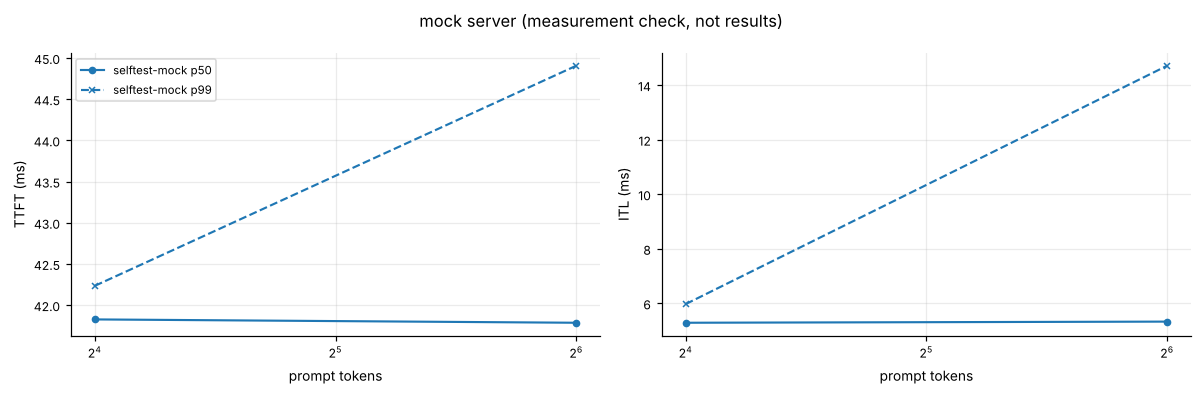

In [10]:
figt, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for label, res in sweeps.items():
    L = [r["prompt_len"] for r in res["results"]]
    for ax, key in ((axes[0], "ttft"), (axes[1], "itl")):
        p50 = [r[f"{key}_p50_ms"] for r in res["results"]]
        p99 = [r[f"{key}_p99_ms"] for r in res["results"]]
        line, = ax.plot(L, p50, marker="o", label=f"{label} p50")
        ax.plot(L, p99, marker="x", linestyle="--", color=line.get_color(), label=f"{label} p99")
for ax, t in zip(axes, ("TTFT (ms)", "ITL (ms)")):
    ax.set_xscale("log", base=2); ax.set_xlabel("prompt tokens"); ax.set_ylabel(t)
axes[0].legend()
title = "mock server (measurement check, not results)" if MODE == "local" else f"{MODEL}: {PREFILL_HOST} prefill, {DECODE_HOST} decode"
figt.suptitle(title)
fig("07_ttft_itl", caption="E8 in cluster mode; a mock server with known delays in local mode")

## 6. Connector telemetry from the running servers

With `metrics_port` set in `kv_connector_extra_config` (launch.sh sets 9464), each worker serves Prometheus text on `metrics_port + rank`: per-class ops, bytes, QP error/reconnect/TCP-fallback events, completion latency histogram.

In [11]:
if MODE == "cluster":
    for host in (PREFILL_HOST, DECODE_HOST):
        try:
            txt = urllib.request.urlopen(f"http://{host}:9464/metrics", timeout=5).read().decode()
            print(f"# {host}"); print("\n".join(l for l in txt.splitlines() if not l.startswith("#"))[:3000])
        except Exception as e:
            print(host, "metrics not reachable:", e)
else:
    print("local mode: see the loopback telemetry table above")

local mode: see the loopback telemetry table above
